In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

bike_df = pd.read_csv("../../datasets/raw/bike_sharing/hour.csv")

# Create cyclic hour features
bike_df["hour_sin"] = np.sin(2 * np.pi * bike_df["hr"] / 24)
bike_df["hour_cos"] = np.cos(2 * np.pi * bike_df["hr"] / 24)

# Select features for clustering
features = ["hour_sin", "hour_cos", "temp", "hum", "windspeed"]

X = bike_df[features].copy()

display(X.head())

print("Feature shape:", X.shape)
print("\nMissing values:")
print(X.isnull().sum())

,hour_sin,hour_cos,temp,hum,windspeed
0,0.000000,1.000000,0.24,0.81,0.0
1,0.258819,0.965926,0.22,0.80,0.0
2,0.500000,0.866025,0.22,0.80,0.0
3,0.707107,0.707107,0.24,0.75,0.0
4,0.866025,0.500000,0.24,0.75,0.0


Feature shape: (17379, 5)

Missing values:
hour_sin     0
hour_cos     0
temp         0
hum          0
windspeed    0
dtype: int64


In [2]:
# Calculate mean and standard deviation
mean = X.mean()
std = X.std()

# Standardize features
X_scaled = (X - mean) / std

# Convert to NumPy array
X_scaled = X_scaled.to_numpy()

print("Scaled data shape:", X_scaled.shape)

print("\nFeature means:")
print(X_scaled.mean(axis=0))

print("\nFeature standard deviations:")
print(X_scaled.std(axis=0))

Scaled data shape: (17379, 5)

Feature means:
[-3.82787063e-17  8.33034596e-18  6.54162137e-17 -2.99279177e-16
  1.68446750e-16]

Feature standard deviations:
[0.99997123 0.99997123 0.99997123 0.99997123 0.99997123]


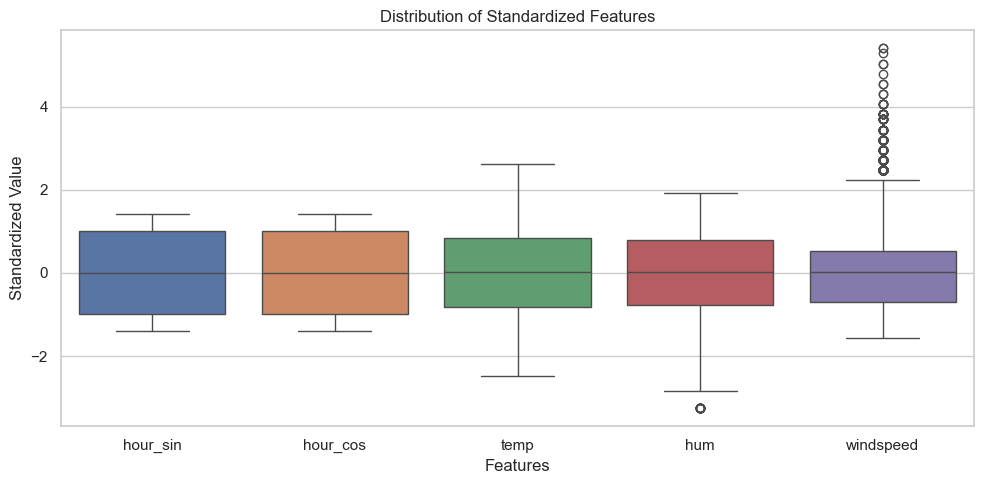

In [3]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=X_scaled)

plt.xticks(range(len(features)), features)
plt.title("Distribution of Standardized Features")
plt.xlabel("Features")
plt.ylabel("Standardized Value")
plt.tight_layout()
plt.show()